# Notebook 4: One Filesystem, Many Storage Places

## What this notebook is about, in one paragraph

So far each agent had **one** kind of storage: memory (Notebook 1), your disk (Notebook 2) or a store
(Notebook 3). Real assistants need **several at once**: scratch paper that disappears, memories that last
forever, and company documents that live on a disk. `CompositeBackend` lets one agent use all of them through
**one** set of folders. The agent just sees folders; behind each folder sits a different storage place.

## How to use this notebook

* Run the cells **from top to bottom**, one at a time (Shift + Enter).
* Before each code cell, read **what we are about to do** and **what to look for**.
* After each code cell, read **what just happened**.

## Words you will see (with everyday comparisons)

| Word | What it means | Everyday comparison |
|---|---|---|
| **Route** | A rule "files whose name starts with X go to storage place Y" | A label on a mail slot: "Invoices go to accounting" |
| **Prefix** | The beginning of a file name, like `/memories/` | The first part of an address, like the street |
| **Default** | Where a file goes when no route matches | The general inbox |
| **`CompositeBackend`** | The backend that reads the routes and sends each file to the right place | The mail room |

## The big idea: a mail room for files

Imagine an office mail room. Every letter has an address. The mail room looks at the **start of the address**
and puts the letter in the right slot:

* addresses starting with `/memories/` go to the **long term store**
* addresses starting with `/docs/` go to a **folder on disk**
* everything else goes to the **general inbox** (memory, thrown away after the conversation)

The agent writes letters. It never needs to know which slot they end up in.

**Diagram: the mail room sends each file to a storage place based on how its name starts**

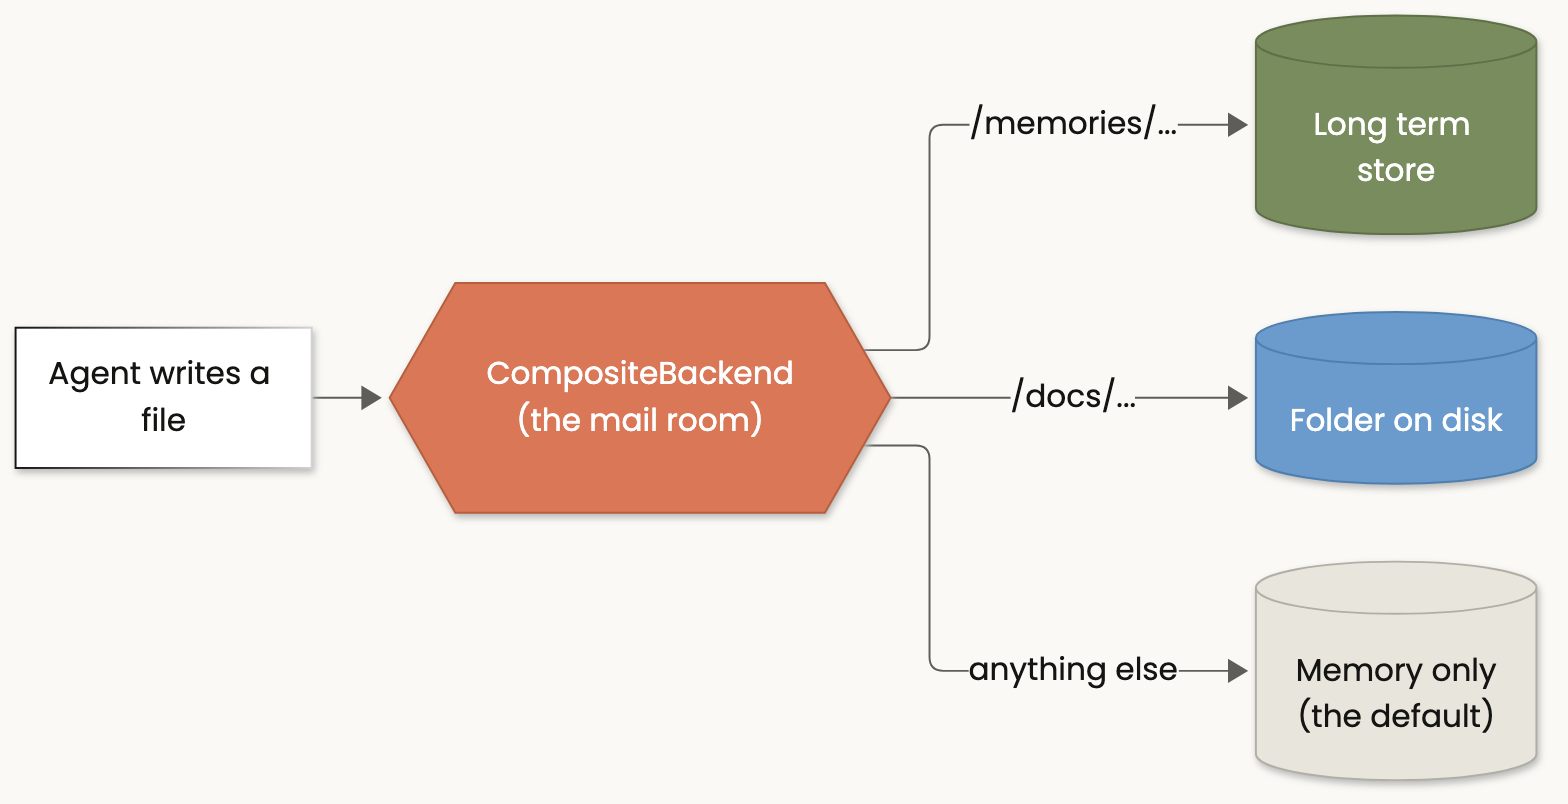

<details><summary>Mermaid source (also saved as diagrams/nb04v3_mailroom.mmd)</summary>

```mermaid
flowchart LR
    A["Agent writes a file"] --> R{{"CompositeBackend<br/>(the mail room)"}}
    R -->|"/memories/..."| ST[("Long term store")]
    R -->|"/docs/..."| D[("Folder on disk")]
    R -->|"anything else"| M[("Memory only<br/>(the default)")]
    class R orange
    class ST green
    class D blue
    class M soft

classDef orange fill:#D97757,stroke:#B65F3F,color:#FFFFFF
classDef green fill:#788C5D,stroke:#5F7048,color:#FFFFFF
classDef blue fill:#6A9BCC,stroke:#4F7FAE,color:#FFFFFF
classDef dark fill:#141413,stroke:#141413,color:#FAF9F5
classDef soft fill:#E8E6DC,stroke:#B0AEA5,color:#141413
classDef bad fill:#F7E3DA,stroke:#D97757,color:#141413

```

</details>

---
# Part 1: Build a mail room by hand

Before involving any AI, we build a small mail room ourselves and drop three files into it.

The rules (routes) are:

| If the file name starts with | It goes to |
|---|---|
| `/memories/` | the store, drawer `('alice', 'memories')` |
| `/memories/projects/` | a real folder on disk, `playground/routing_lab/project_memories/` |
| `/docs/` | a real folder on disk, `playground/routing_lab/docs/` |
| anything else | the store, drawer `('scratch',)` (the general inbox for this demo) |

Note: in a real agent the general inbox is memory (`StateBackend`). Memory only works while an agent is running,
so for this hand made demo we use a store drawer instead.

In [1]:
# Load the class helpers (the reload line makes sure we always use the latest version)
import importlib, course_utils
importlib.reload(course_utils)

from course_utils import MODEL, show_trace, show_store, show_folder, files_in, where_did_files_go
from deepagents import create_deep_agent
from deepagents.backends import CompositeBackend, StateBackend, StoreBackend, FilesystemBackend
from langgraph.store.memory import InMemoryStore
from langgraph.checkpoint.memory import InMemorySaver
from pathlib import Path
import shutil

LAB = Path.cwd() / "playground" / "routing_lab"
shutil.rmtree(LAB, ignore_errors=True)
(LAB / "project_memories").mkdir(parents=True)
(LAB / "docs").mkdir(parents=True)
(LAB / "docs" / "handbook.md").write_text("Refund window is 30 days.\n")    # a document that already exists

store = InMemoryStore()

routes = {
    "/memories/":          StoreBackend(store=store, namespace=lambda _rt: ("alice", "memories")),
    "/memories/projects/": FilesystemBackend(root_dir=str(LAB / "project_memories"), virtual_mode=True),
    "/docs/":              FilesystemBackend(root_dir=str(LAB / "docs"), virtual_mode=True),
}
mail_room = CompositeBackend(
    default=StoreBackend(store=store, namespace=lambda _rt: ("scratch",)),   # the general inbox
    routes=routes,
)
print("Mail room is ready with", len(routes), "routes plus a default.")

Mail room is ready with 3 routes plus a default.


### Drop three files into the mail room

**Predict first** using the table above: where will each of these three files end up?

1. `/draft.md`
2. `/memories/prefs.md`
3. `/memories/projects/apollo.md`

In [2]:
for name in ["/draft.md", "/memories/prefs.md", "/memories/projects/apollo.md"]:
    mail_room.write(name, f"refund notes written as {name}")
    print("Wrote", name)

print()
print("1) What is now in the STORE:")
show_store(store)
print()
print("2) What is now on your DISK:")
show_folder(LAB)

Wrote /draft.md
Wrote /memories/prefs.md
Wrote /memories/projects/apollo.md

1) What is now in the STORE:
The store holds 2 file(s):
  drawer ('scratch',)  file /draft.md
      content: refund notes written as /draft.md
  drawer ('alice', 'memories')  file /prefs.md
      content: refund notes written as /memories/prefs.md

2) What is now on your DISK:
Folder on your Mac: /Users/datasense/Desktop/deepagents/notebooks/playground/routing_lab
    docs/
        handbook.md
    project_memories/
        apollo.md


### What just happened, file by file

| Agent's name | Which rule matched | Where it really is | Saved under the name |
|---|---|---|---|
| `/draft.md` | none, so the default | store, drawer `('scratch',)` | `/draft.md` |
| `/memories/prefs.md` | `/memories/` | store, drawer `('alice', 'memories')` | `/prefs.md` |
| `/memories/projects/apollo.md` | `/memories/projects/` (the longer one wins) | disk, `routing_lab/project_memories/apollo.md` | `apollo.md` |

Two surprises are worth explaining. They are the two rules of the mail room.

---
# Part 2: Mail room rule 1: the longest matching rule wins

`/memories/projects/apollo.md` starts with **both** `/memories/` and `/memories/projects/`.
The mail room always picks the **most specific** rule, the longest one. So `apollo.md` went to the project folder
on disk, not to the store.

Here is the same decision written as a few lines of code, so you can see the logic:

In [3]:
def which_rule(file_name, rules):
    matching = [rule for rule in rules if file_name.startswith(rule)]
    return max(matching, key=len) if matching else "(no rule, so the default)"

for name in ["/draft.md", "/memories/prefs.md", "/memories/projects/apollo.md", "/docs/handbook.md"]:
    print(f"{name:32} -> rule {which_rule(name, routes)}")

/draft.md                        -> rule (no rule, so the default)
/memories/prefs.md               -> rule /memories/
/memories/projects/apollo.md     -> rule /memories/projects/
/docs/handbook.md                -> rule /docs/


**Diagram: when two rules match, the longer one wins**

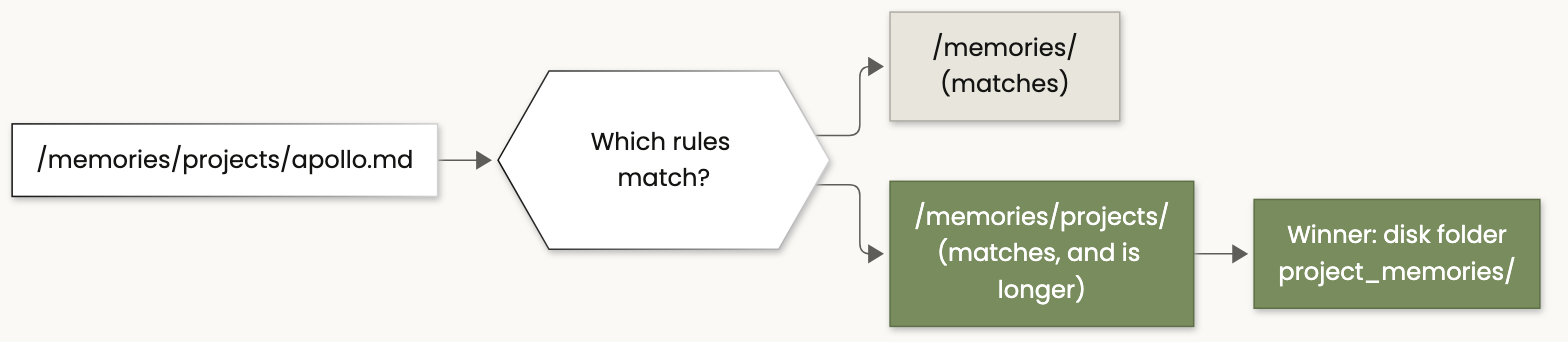

<details><summary>Mermaid source (also saved as diagrams/nb04v3_longest.mmd)</summary>

```mermaid
flowchart LR
    P["/memories/projects/apollo.md"] --> Q{{"Which rules match?"}}
    Q --> R1["/memories/<br/>(matches)"]
    Q --> R2["/memories/projects/<br/>(matches, and is longer)"]
    R2 --> W["Winner: disk folder<br/>project_memories/"]
    class R2,W green
    class R1 soft

classDef orange fill:#D97757,stroke:#B65F3F,color:#FFFFFF
classDef green fill:#788C5D,stroke:#5F7048,color:#FFFFFF
classDef blue fill:#6A9BCC,stroke:#4F7FAE,color:#FFFFFF
classDef dark fill:#141413,stroke:#141413,color:#FAF9F5
classDef soft fill:#E8E6DC,stroke:#B0AEA5,color:#141413
classDef bad fill:#F7E3DA,stroke:#D97757,color:#141413

```

</details>

---
# Part 3: Mail room rule 2: the slot name is removed from the file name

Look again at the store listing above: the file `/memories/prefs.md` is saved as **`/prefs.md`**.
The mail room **removes the route part** (`/memories`) before handing the file over.

Everyday comparison: a letter to "Accounting, invoice 42" arrives at the accounting desk simply as "invoice 42".
The accounting desk does not need to know it is called "Accounting".

Let us prove it by asking the store directly:

In [4]:
print("Is there a file called '/memories/prefs.md' in Alice's drawer?", store.get(("alice", "memories"), "/memories/prefs.md") is not None)
print("Is there a file called '/prefs.md' in Alice's drawer?         ", store.get(("alice", "memories"), "/prefs.md") is not None)

Is there a file called '/memories/prefs.md' in Alice's drawer? False
Is there a file called '/prefs.md' in Alice's drawer?          True


And the other way round: when the agent **lists** files, the mail room **puts the route part back**, so the agent
always sees the full names. It also combines all storage places into one view:

In [5]:
print("What the agent sees when it lists '/':")
for entry in mail_room.ls("/").entries:
    print("   ", entry["path"])

print()
print("What the agent finds when it searches every place for the word 'efund':")
for match in mail_room.grep("efund").matches:
    print(f"    {match['path']}  ->  {match['text']}")

What the agent sees when it lists '/':
    /docs/
    /draft.md
    /memories/
    /memories/projects/

What the agent finds when it searches every place for the word 'efund':
    /draft.md  ->  refund notes written as /draft.md
    /memories/prefs.md  ->  refund notes written as /memories/prefs.md
    /memories/projects/apollo.md  ->  refund notes written as /memories/projects/apollo.md
    /docs/handbook.md  ->  Refund window is 30 days.


### What just happened

* The list shows `/docs/`, `/draft.md`, `/memories/` and `/memories/projects/`, as if it were one folder tree.
* The search found matches in **three different storage places** (store, store, and two disk folders) and showed
  them all with their full agent names.

So for the agent it really is **one** filesystem.

**Diagram: the route part is removed on the way in and added back on the way out**

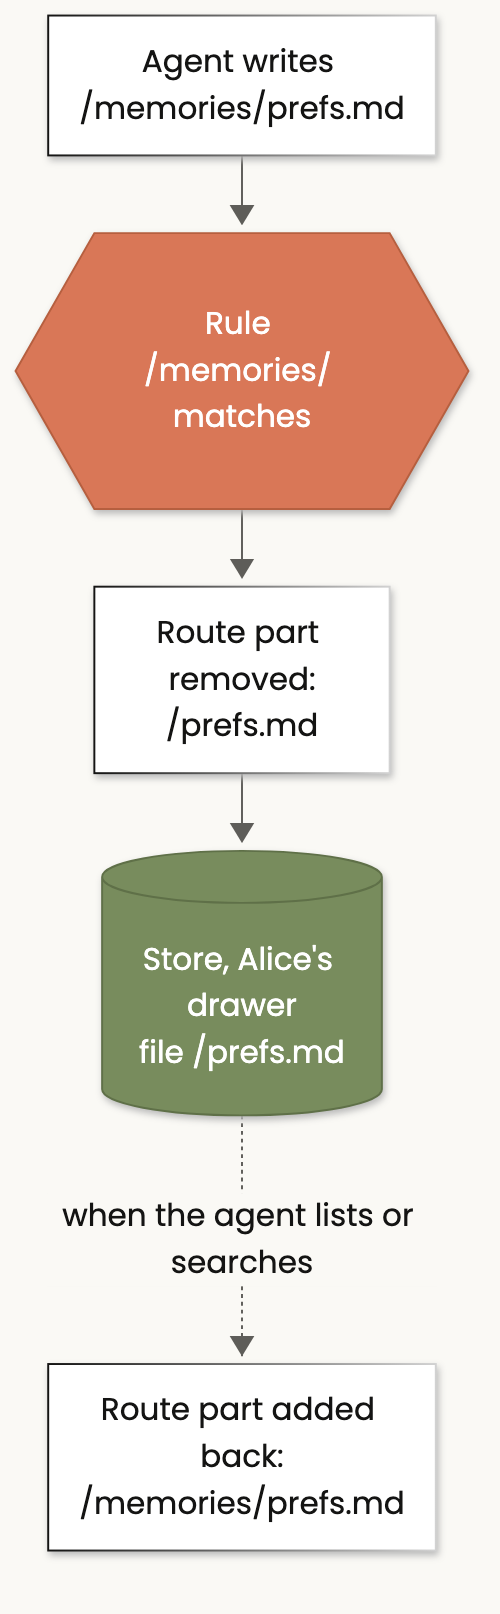

<details><summary>Mermaid source (also saved as diagrams/nb04v3_strip.mmd)</summary>

```mermaid
flowchart TB
    P["Agent writes /memories/prefs.md"] --> M{{"Rule /memories/ matches"}}
    M --> S["Route part removed:<br/>/prefs.md"]
    S --> K[("Store, Alice's drawer<br/>file /prefs.md")]
    K -. "when the agent lists or searches" .-> BACK["Route part added back:<br/>/memories/prefs.md"]
    class M orange
    class K green

classDef orange fill:#D97757,stroke:#B65F3F,color:#FFFFFF
classDef green fill:#788C5D,stroke:#5F7048,color:#FFFFFF
classDef blue fill:#6A9BCC,stroke:#4F7FAE,color:#FFFFFF
classDef dark fill:#141413,stroke:#141413,color:#FAF9F5
classDef soft fill:#E8E6DC,stroke:#B0AEA5,color:#141413
classDef bad fill:#F7E3DA,stroke:#D97757,color:#141413

```

</details>

---
# Part 4: A real assistant with three storage places

**The story:** Northwind is a company. Its employees use an internal assistant that should:

1. **remember** each employee's preferences forever, in the store, one drawer per employee
2. **read** the company's policy documents, which are files on disk maintained by HR
3. **never change** those policy documents
4. keep drafts and big tool answers as **scratch paper** that disappears after the conversation

| Route | Storage place | Why |
|---|---|---|
| `/memories/` | store, drawer `(employee, "memories")` | remembered forever, private per employee |
| `/docs/` | disk folder `playground/northwind_docs/` | the real policy files |
| anything else | memory only | scratch paper |

Point 3 is done with a **permission rule**: "writing to `/docs/` is denied". Notebook 5 explains permissions in depth.

First we create the two policy documents on disk:

In [6]:
DOCS = Path.cwd() / "playground" / "northwind_docs"
shutil.rmtree(DOCS, ignore_errors=True)
DOCS.mkdir(parents=True)

(DOCS / "travel_policy.md").write_text("""# Travel policy
* Economy class for flights under 6 hours, premium economy above 6 hours.
* Hotel cap: 180 EUR per night in Europe, 250 USD per night in the US.
* Book through the internal portal at least 14 days in advance.
""")
(DOCS / "expense_policy.md").write_text("""# Expense policy
* Submit receipts within 30 days.
* Client dinners up to 75 EUR per person need no pre approval.
* Alcohol is not reimbursable except at client dinners.
""")
show_folder(DOCS)

Folder on your Mac: /Users/datasense/Desktop/deepagents/notebooks/playground/northwind_docs
    expense_policy.md
    travel_policy.md


Now the assistant itself. Each line of the `routes` matches one row of the table above.

In [7]:
from dataclasses import dataclass
from deepagents import FilesystemPermission

@dataclass
class Employee:                 # the "visitor badge": who is talking
    user_id: str

store = InMemoryStore()

assistant = create_deep_agent(
    model=MODEL,
    backend=CompositeBackend(
        default=StateBackend(),                                                          # scratch paper: memory
        routes={
            "/memories/": StoreBackend(namespace=lambda rt: (rt.context.user_id, "memories")),   # long term, per employee
            "/docs/": FilesystemBackend(root_dir=str(DOCS), virtual_mode=True),                  # policy files on disk
        },
    ),
    store=store,
    checkpointer=InMemorySaver(),
    context_schema=Employee,
    permissions=[FilesystemPermission(operations=["write"], paths=["/docs/**"], mode="deny")],   # docs are read only
    system_prompt=(
        "You are Northwind's internal assistant.\n"
        "* Company policies are in /docs/ (read only).\n"
        "* Long term notes about this employee are in /memories/. Read /memories/ at the start of every "
        "conversation and save lasting preferences there.\n"
        "* Use any other path, such as /drafts/, for temporary work."
    ),
)
print("Northwind assistant is ready.")

Northwind assistant is ready.


**Diagram: the Northwind assistant: three storage places behind one set of folders**

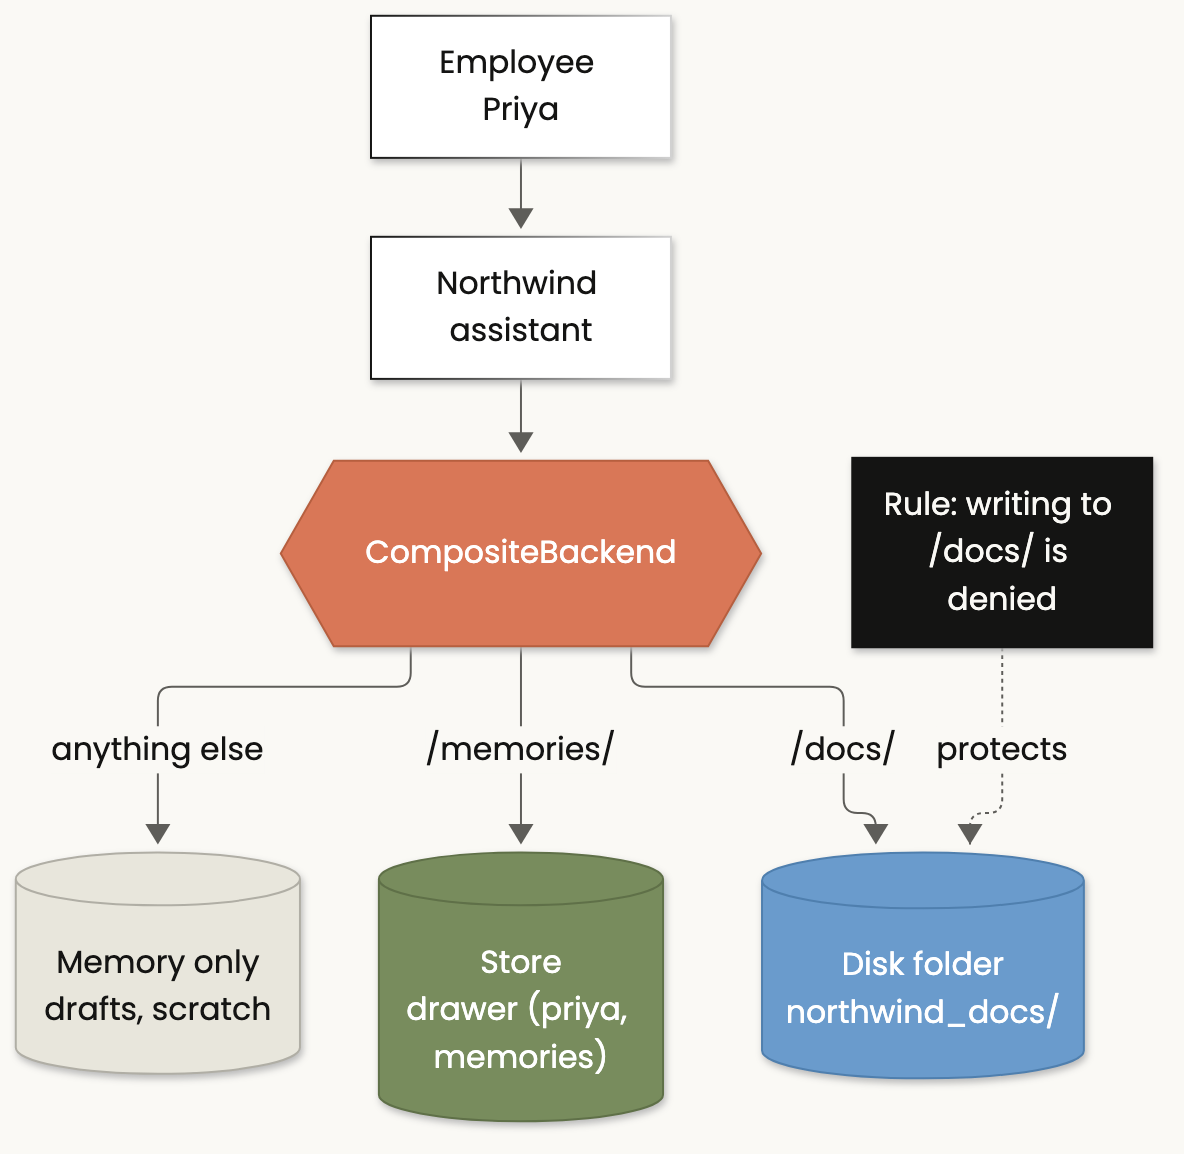

<details><summary>Mermaid source (also saved as diagrams/nb04v3_northwind.mmd)</summary>

```mermaid
flowchart TB
    E["Employee Priya"] --> AG["Northwind assistant"]
    AG --> CB{{"CompositeBackend"}}
    CB -->|"anything else"| SB[("Memory only<br/>drafts, scratch")]
    CB -->|"/memories/"| ST[("Store<br/>drawer (priya, memories)")]
    CB -->|"/docs/"| FS[("Disk folder<br/>northwind_docs/")]
    PERM["Rule: writing to /docs/ is denied"] -. "protects" .-> FS
    class CB orange
    class SB soft
    class ST green
    class FS blue
    class PERM dark

classDef orange fill:#D97757,stroke:#B65F3F,color:#FFFFFF
classDef green fill:#788C5D,stroke:#5F7048,color:#FFFFFF
classDef blue fill:#6A9BCC,stroke:#4F7FAE,color:#FFFFFF
classDef dark fill:#141413,stroke:#141413,color:#FAF9F5
classDef soft fill:#E8E6DC,stroke:#B0AEA5,color:#141413
classDef bad fill:#F7E3DA,stroke:#D97757,color:#141413

```

</details>

### Conversation 1: Priya shares a preference

**What to look for:** the agent should save the preference under `/memories/`, and the table should say it went
to the **store**.

In [8]:
run1 = assistant.invoke(
    {"messages": [{"role": "user", "content": "Remember for the future: I'm based in Berlin and I always want answers as max 3 bullets."}]},
    config={"configurable": {"thread_id": "conversation-1"}},
    context=Employee(user_id="priya"),
)
show_trace(run1)
print()
where_did_files_go(run1, label="nb04_conversation1",
                   store_folders={"/memories/": (store, ("priya", "memories"))},
                   disk_folders={"/docs/": DOCS})

WHAT THE AGENT DID, STEP BY STEP
Step 1. The agent LOOKED INSIDE the folder /memories
         It got back: No files found
Step 2. The agent CREATED (or replaced) the file /memories/employee_prefs.txt
         It got back: Updated file /memories/employee_prefs.txt
THE AGENT'S REPLY TO YOU:
Got it - I’ll remember that you’re based in Berlin and I should keep answers to 3 bullets max.

Note: file names in the steps above (starting with /) are the AGENT'S names for files,
not places on your Mac. See 'WHERE DID THE FILES GO?' for where they really are.

WHERE DID THE FILES GO?
------------------------------------------------------------------------------
Agent's name for it : /memories/employee_prefs.txt
Where it really is  : IN THE STORE (a database), drawer ('priya', 'memories'), file /employee_prefs.txt
Copy you can open   : /Users/datasense/Desktop/deepagents/notebooks/agent_files/nb04_conversation1/memories/employee_prefs.txt
-----------------------------------------------------------

### Conversation 2 (a new conversation): a policy question

**What to look for:** the agent should (1) read Priya's preferences from the store, (2) read the travel policy
from disk, (3) write a draft checklist as scratch paper, and (4) answer in at most 3 bullets.

In [9]:
run2 = assistant.invoke(
    {"messages": [{"role": "user", "content": "I'm flying to New York for a client. What class can I book and what's my hotel limit? Also save a draft of a trip checklist."}]},
    config={"configurable": {"thread_id": "conversation-2"}},
    context=Employee(user_id="priya"),
)
show_trace(run2, limit=200)
print()
where_did_files_go(run2, label="nb04_conversation2",
                   store_folders={"/memories/": (store, ("priya", "memories"))},
                   disk_folders={"/docs/": DOCS})

WHAT THE AGENT DID, STEP BY STEP
Step 1. The agent LOOKED INSIDE the folder /memories
         It got back: ['/memories/employee_prefs.txt']
Step 2. The agent LOOKED INSIDE the folder /docs
         It got back: ['/docs/expense_policy.md', '/docs/travel_policy.md']
Step 3. The agent OPENED and read the file /memories/employee_prefs.txt
         It got back: (lines 1 to 3 of 3) User preferences: / - Based in Berlin. / - Wants answers in max 3 bullets.
Step 4. The agent OPENED and read the file /docs/travel_policy.md
         It got back: (lines 1 to 4 of 4) # Travel policy / * Economy class for flights under 6 hours, premium economy above 6 hours. / * Hotel cap: 180 EUR per night in Europe, 250 USD per night in the US. / * Book throug ...
Step 5. The agent OPENED and read the file /docs/expense_policy.md
         It got back: (lines 1 to 4 of 4) # Expense policy / * Submit receipts within 30 days. / * Client dinners up to 75 EUR per person need no pre approval. / * Alcohol is not reimbu

### What just happened

In one conversation the agent used **all three** storage places without knowing it:

* it **read** Priya's preferences from the **store** (written in conversation 1)
* it **read** the policy from the **disk folder**
* it **wrote** a draft checklist to **memory only** (it disappears after this conversation; we saved a copy so you can look)

### Conversation 3: someone asks the agent to change a policy

**What to look for:** the agent will try, and the step should say **NOT DONE** because of the permission rule.
Then we check that the real file on disk is unchanged.

In [10]:
run3 = assistant.invoke(
    {"messages": [{"role": "user", "content": "Update /docs/travel_policy.md so the hotel cap in the US is 400 USD."}]},
    config={"configurable": {"thread_id": "conversation-3"}},
    context=Employee(user_id="priya"),
)
show_trace(run3)
print()
print("The real policy file on disk:", DOCS / "travel_policy.md")
print((DOCS / "travel_policy.md").read_text())

WHAT THE AGENT DID, STEP BY STEP
Step 1. The agent LOOKED INSIDE the folder /memories
         It got back: ['/memories/employee_prefs.txt']
Step 2. The agent OPENED and read the file /memories/employee_prefs.txt
         It got back: (lines 1 to 3 of 3) User preferences: / - Based in Berlin. / - Wants answers in max 3 bullets.
Step 3. The agent OPENED and read the file /docs/travel_policy.md
         It got back: (lines 1 to 4 of 4) # Travel policy / * Economy class for flights under 6 hours, premium economy above 6 hours. / * Hotel cap: 180 EUR per night in Europe, 250  ...
Step 4. The agent TRIED to change the file /docs/travel_policy.md
         NOT DONE. Reason: Error: permission denied for write on /docs/travel_policy.md
Step 5. The agent CREATED (or replaced) the file /drafts/travel_policy.md
         It got back: Updated file /drafts/travel_policy.md
THE AGENT'S REPLY TO YOU:
- I couldn’t modify `/docs/travel_policy.md` directly because it’s read-only here.
- I prepared the upd

The file still says **250 USD**. The permission rule stopped the change **before** anything touched the disk.

---
# Part 5: Why the default should be memory

The default route is where **everything without a matching rule** goes. That includes the agent's own scratch
paper, like the huge tool answers we saw in Notebooks 1 and 2.

| If the default is | Then the agent's scratch paper is |
|---|---|
| memory (`StateBackend`) | thrown away after the conversation. Good. |
| a disk folder (`FilesystemBackend`) | written into that folder, mixed with your files (Notebook 2, Part 5) |
| a store (`StoreBackend`) | kept forever in your database, growing and possibly holding sensitive data |

> **Rule:** make the default `StateBackend()`, then add a route for each folder you really want to keep.

---
# Part 6: `ContextHubBackend`: a folder with a history of every change

There is one more storage place on the official page. `ContextHubBackend` keeps the agent's files in a
**LangSmith Context Hub repository**. Think of it like Google Docs version history, but for the agent's files:
**every change is saved as a new version** (called a *commit*), so you can see who changed what and go back.

Typical contents are the agent's instructions (`AGENTS.md`) and reusable **skills** (`SKILL.md` files). A skill,
for example "how to format emails", can live in its own repository and be shared by many agents.

**Diagram: how an agent repository and shared skill repositories appear as one folder tree**

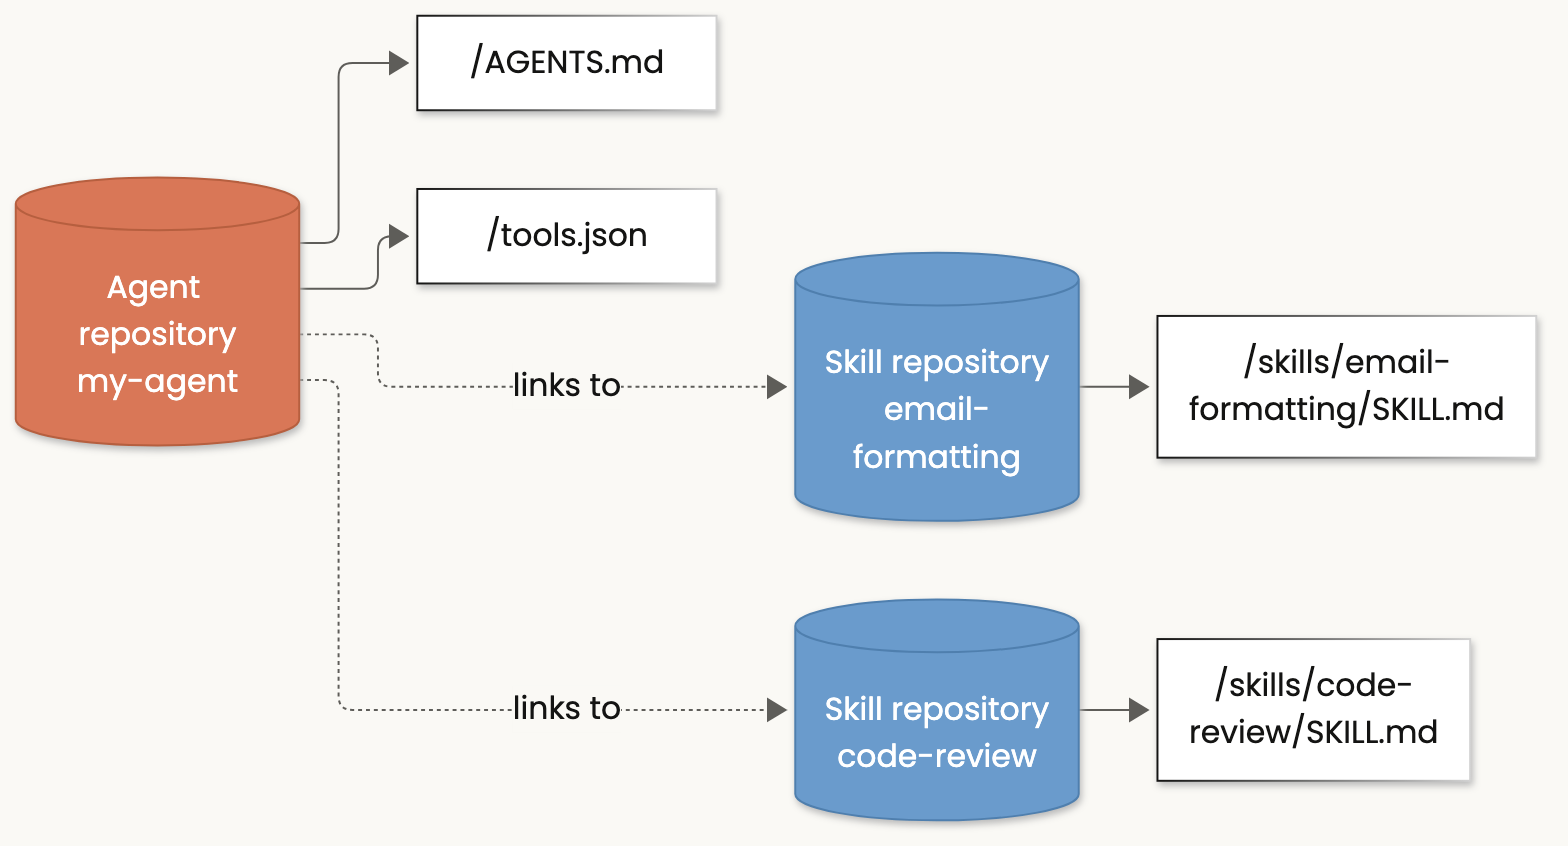

<details><summary>Mermaid source (also saved as diagrams/nb04v3_hub.mmd)</summary>

```mermaid
flowchart LR
    AR[("Agent repository<br/>my-agent")] --> R1["/AGENTS.md"]
    AR --> R2["/tools.json"]
    SR1[("Skill repository<br/>email-formatting")] --> S1["/skills/email-formatting/SKILL.md"]
    SR2[("Skill repository<br/>code-review")] --> S2["/skills/code-review/SKILL.md"]
    AR -. "links to" .-> SR1
    AR -. "links to" .-> SR2
    class AR orange
    class SR1,SR2 blue

classDef orange fill:#D97757,stroke:#B65F3F,color:#FFFFFF
classDef green fill:#788C5D,stroke:#5F7048,color:#FFFFFF
classDef blue fill:#6A9BCC,stroke:#4F7FAE,color:#FFFFFF
classDef dark fill:#141413,stroke:#141413,color:#FAF9F5
classDef soft fill:#E8E6DC,stroke:#B0AEA5,color:#141413
classDef bad fill:#F7E3DA,stroke:#D97757,color:#141413

```

</details>

**What happens if two agents change the same repository at the same time?** The second one is told "someone
changed it before you", reloads the latest version, and tries again. Nothing gets silently overwritten.

| Choose Context Hub when | Choose a store (Notebook 3) when |
|---|---|
| You want a full history of every change | You already run a database like Postgres |
| Instructions and skills should be shared between agents | You need one private drawer per user, at large scale |

It needs a LangSmith account (`LANGSMITH_API_KEY`). The cell below only runs if you have one, so everybody can
run this notebook.

In [11]:
import os

if os.getenv("LANGSMITH_API_KEY"):
    from deepagents.backends import ContextHubBackend
    hub_agent = create_deep_agent(
        model=MODEL,
        backend=CompositeBackend(default=StateBackend(), routes={"/hub/": ContextHubBackend("backends-class-demo")}),
    )
    result = hub_agent.invoke({"messages": [{"role": "user", "content": "Write a one line style guide to /hub/STYLE.md"}]})
    show_trace(result)
else:
    print("No LANGSMITH_API_KEY found, so we skip the live demo.")
    print("The pattern to remember:  routes={'/hub/': ContextHubBackend('owner/my-agent')}")

No LANGSMITH_API_KEY found, so we skip the live demo.
The pattern to remember:  routes={'/hub/': ContextHubBackend('owner/my-agent')}


---
# Summary

## Where did every file end up?

| Part | The agent's name | Where it really is |
|---|---|---|
| 1 | `/draft.md` | store, drawer `('scratch',)` (hand made demo) |
| 1 | `/memories/prefs.md` | store, drawer `('alice', 'memories')`, saved as `/prefs.md` |
| 1 | `/memories/projects/apollo.md` | disk, `playground/routing_lab/project_memories/apollo.md` |
| 4 | `/memories/...` (Priya's preferences) | store, drawer `('priya', 'memories')` |
| 4 | `/docs/travel_policy.md` | disk, `playground/northwind_docs/travel_policy.md` (never changed) |
| 4 | `/drafts/...` | memory only, gone after the conversation |

## The rules

1. `CompositeBackend` sends each file to a storage place based on how its name starts.
2. When two rules match, the **longer** one wins.
3. The route part is removed before storing, and added back when listing.
4. Make the default `StateBackend()` (memory), and add routes only for what must be kept.

## Quick quiz

1. Routes are `/memories/` (store) and `/memories/team/` (disk). Where does `/memories/team/roadmap.md` go?
2. In the store, under which name is `/memories/prefs.md` saved?
3. The default backend is a store. What problem appears after a month?
4. How did Northwind keep its policy files safe from the agent?

<details><summary>Click to see the answers</summary>

1. The disk, because `/memories/team/` is the longer matching rule.
2. `/prefs.md`.
3. All the agent's scratch paper is kept forever, filling the database and maybe keeping sensitive data.
4. With a permission rule that denies writing to `/docs/**`.
</details>

**Next:** Notebook 5 builds a storage place from scratch and adds rules that need code.